# CNN Architecture

## AlexNet(2013)
- 227\*227 inputs
- 5 conv layers
- 5 max pooling layers
- flatten
- 3 fully connected layers
- Relu插在上述层间

### 计算
size, memory, param, flops

### 特征
fc有高的params，conv有高的memory

### zf-net(a bigger version of AlexNet)
第一层stride从4改为2


## VGG(2014)

### VGG Structure
开始有design principles

5 convolutional stages(conv-conv-pool)

1. all conv are 3*3 stride 1 padding 1
用2个3\*3 conv代替5\*5 conv，更少的params, FLOPS，且可以在两层间插入relu引入更多的非线性

2. all maxpool are 2*2 stride 2

3. after pool, double channels in next conv stage, 以保持FLOPS不变

降低分辨率时，可以增加通道特征数，控制卷积的成本

### 为何需要下采样
- 把计算资源从精确位置转向更多特征。 前面需要分辨边缘、纹理的位置；后面做图像分类，更关注“出现了什么部件、如何组合”。降低空间分辨率后，可以在相近的计算成本下增加通道，容纳更多种特征响应。
- 让后续卷积更快覆盖较大的图像区域。 下采样后，相邻位置对应原图中更远的位置，因此后面的 \(3\times3\) 卷积能整合更大范围的信息，便于识别物体整体。

### 对比VGG和AlexNet
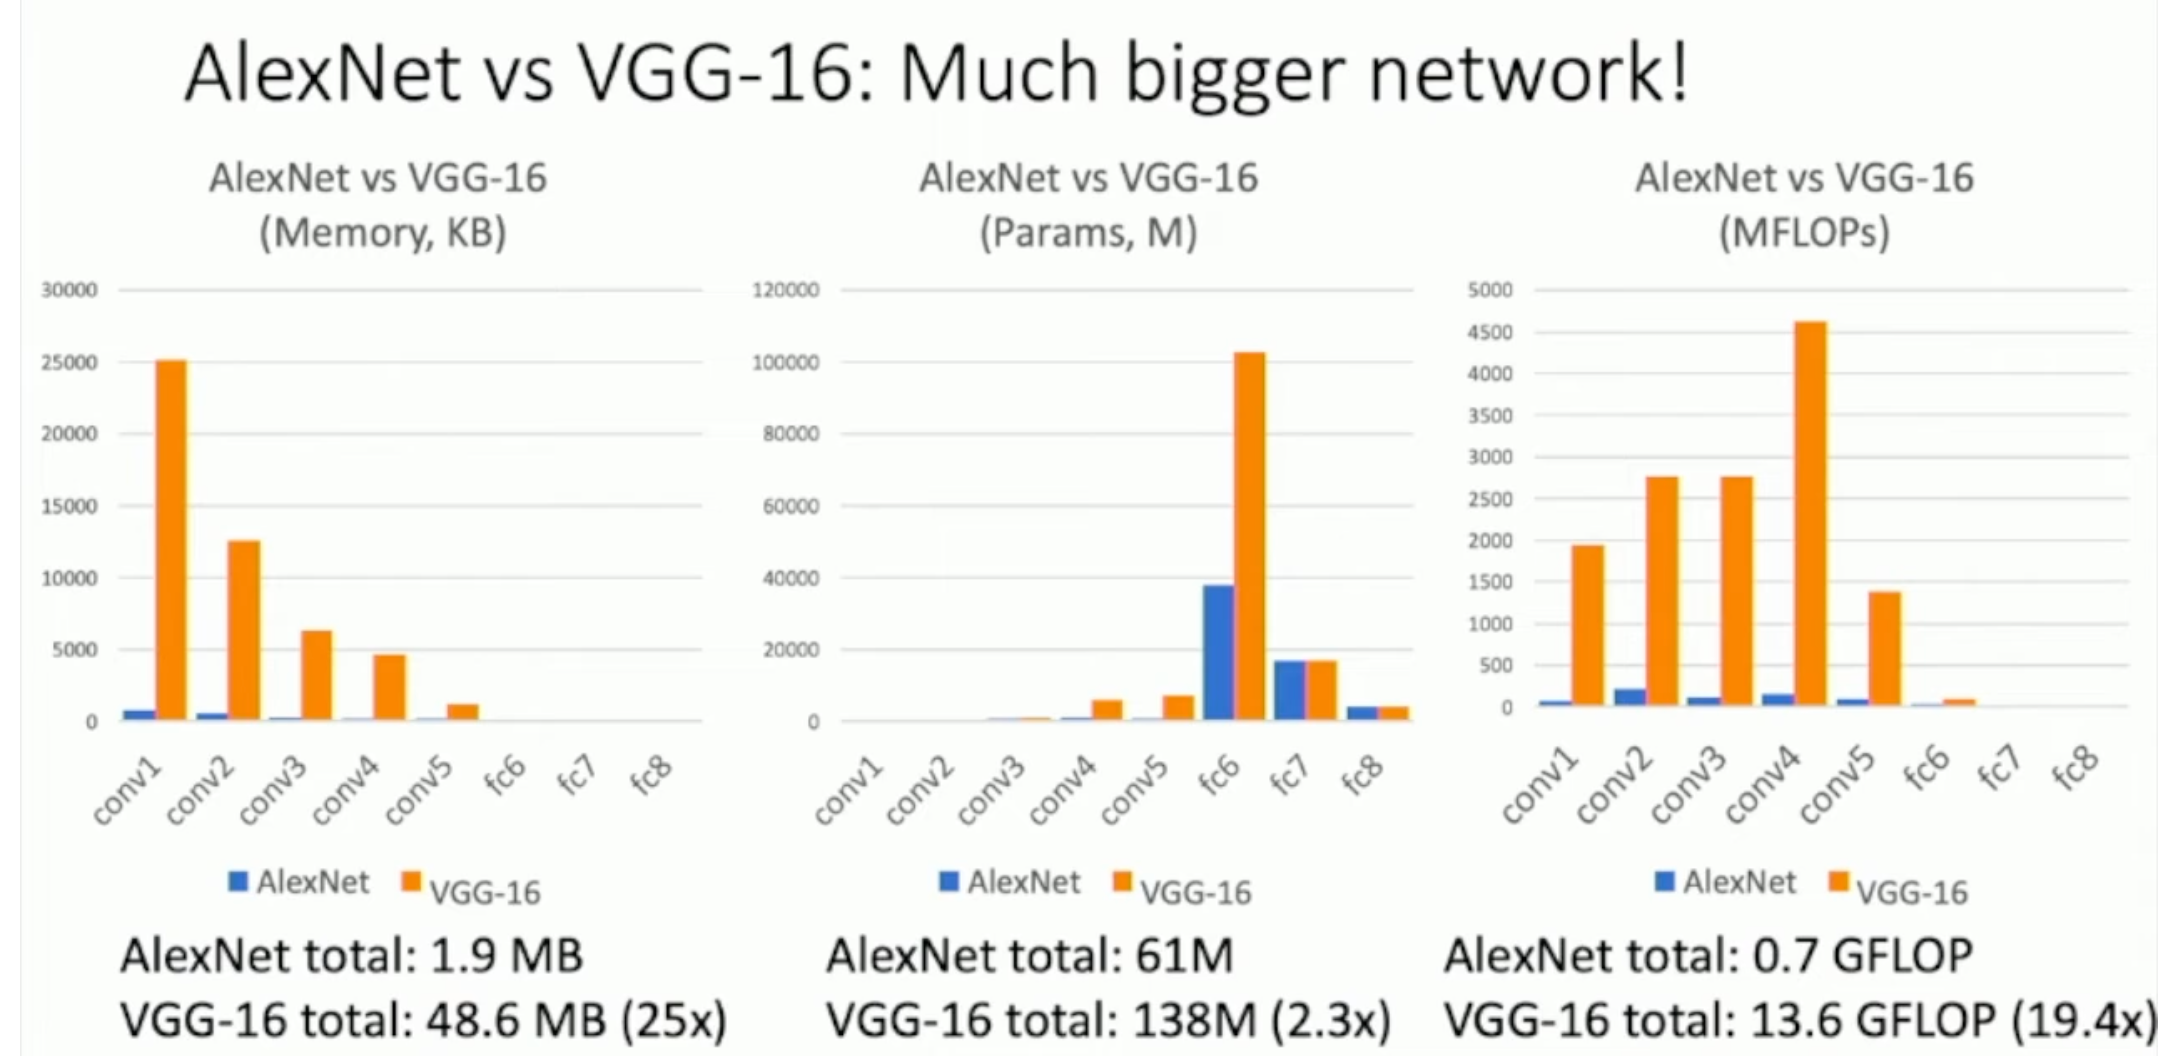



## GoogLeNet(2014)

### Stem Aggressively

1. VGG最大的显存开销在最开始几步conv，google 用多次max pool减小图片size
2. 同时用Bottle Neck Layers(1\* 1)减少通道数
| 方案 | 计算量 |
|---|---:|
| 直接做 \(5\times5\)，\(192\to32\) | \(25\times192\times32=153600\) |
| 先用 \(1\times1\) 做 \(192\to16\)，再用 \(5\times5\) 做 \(16\to32\) | \(192\times16+25\times16\times32=15872\) |
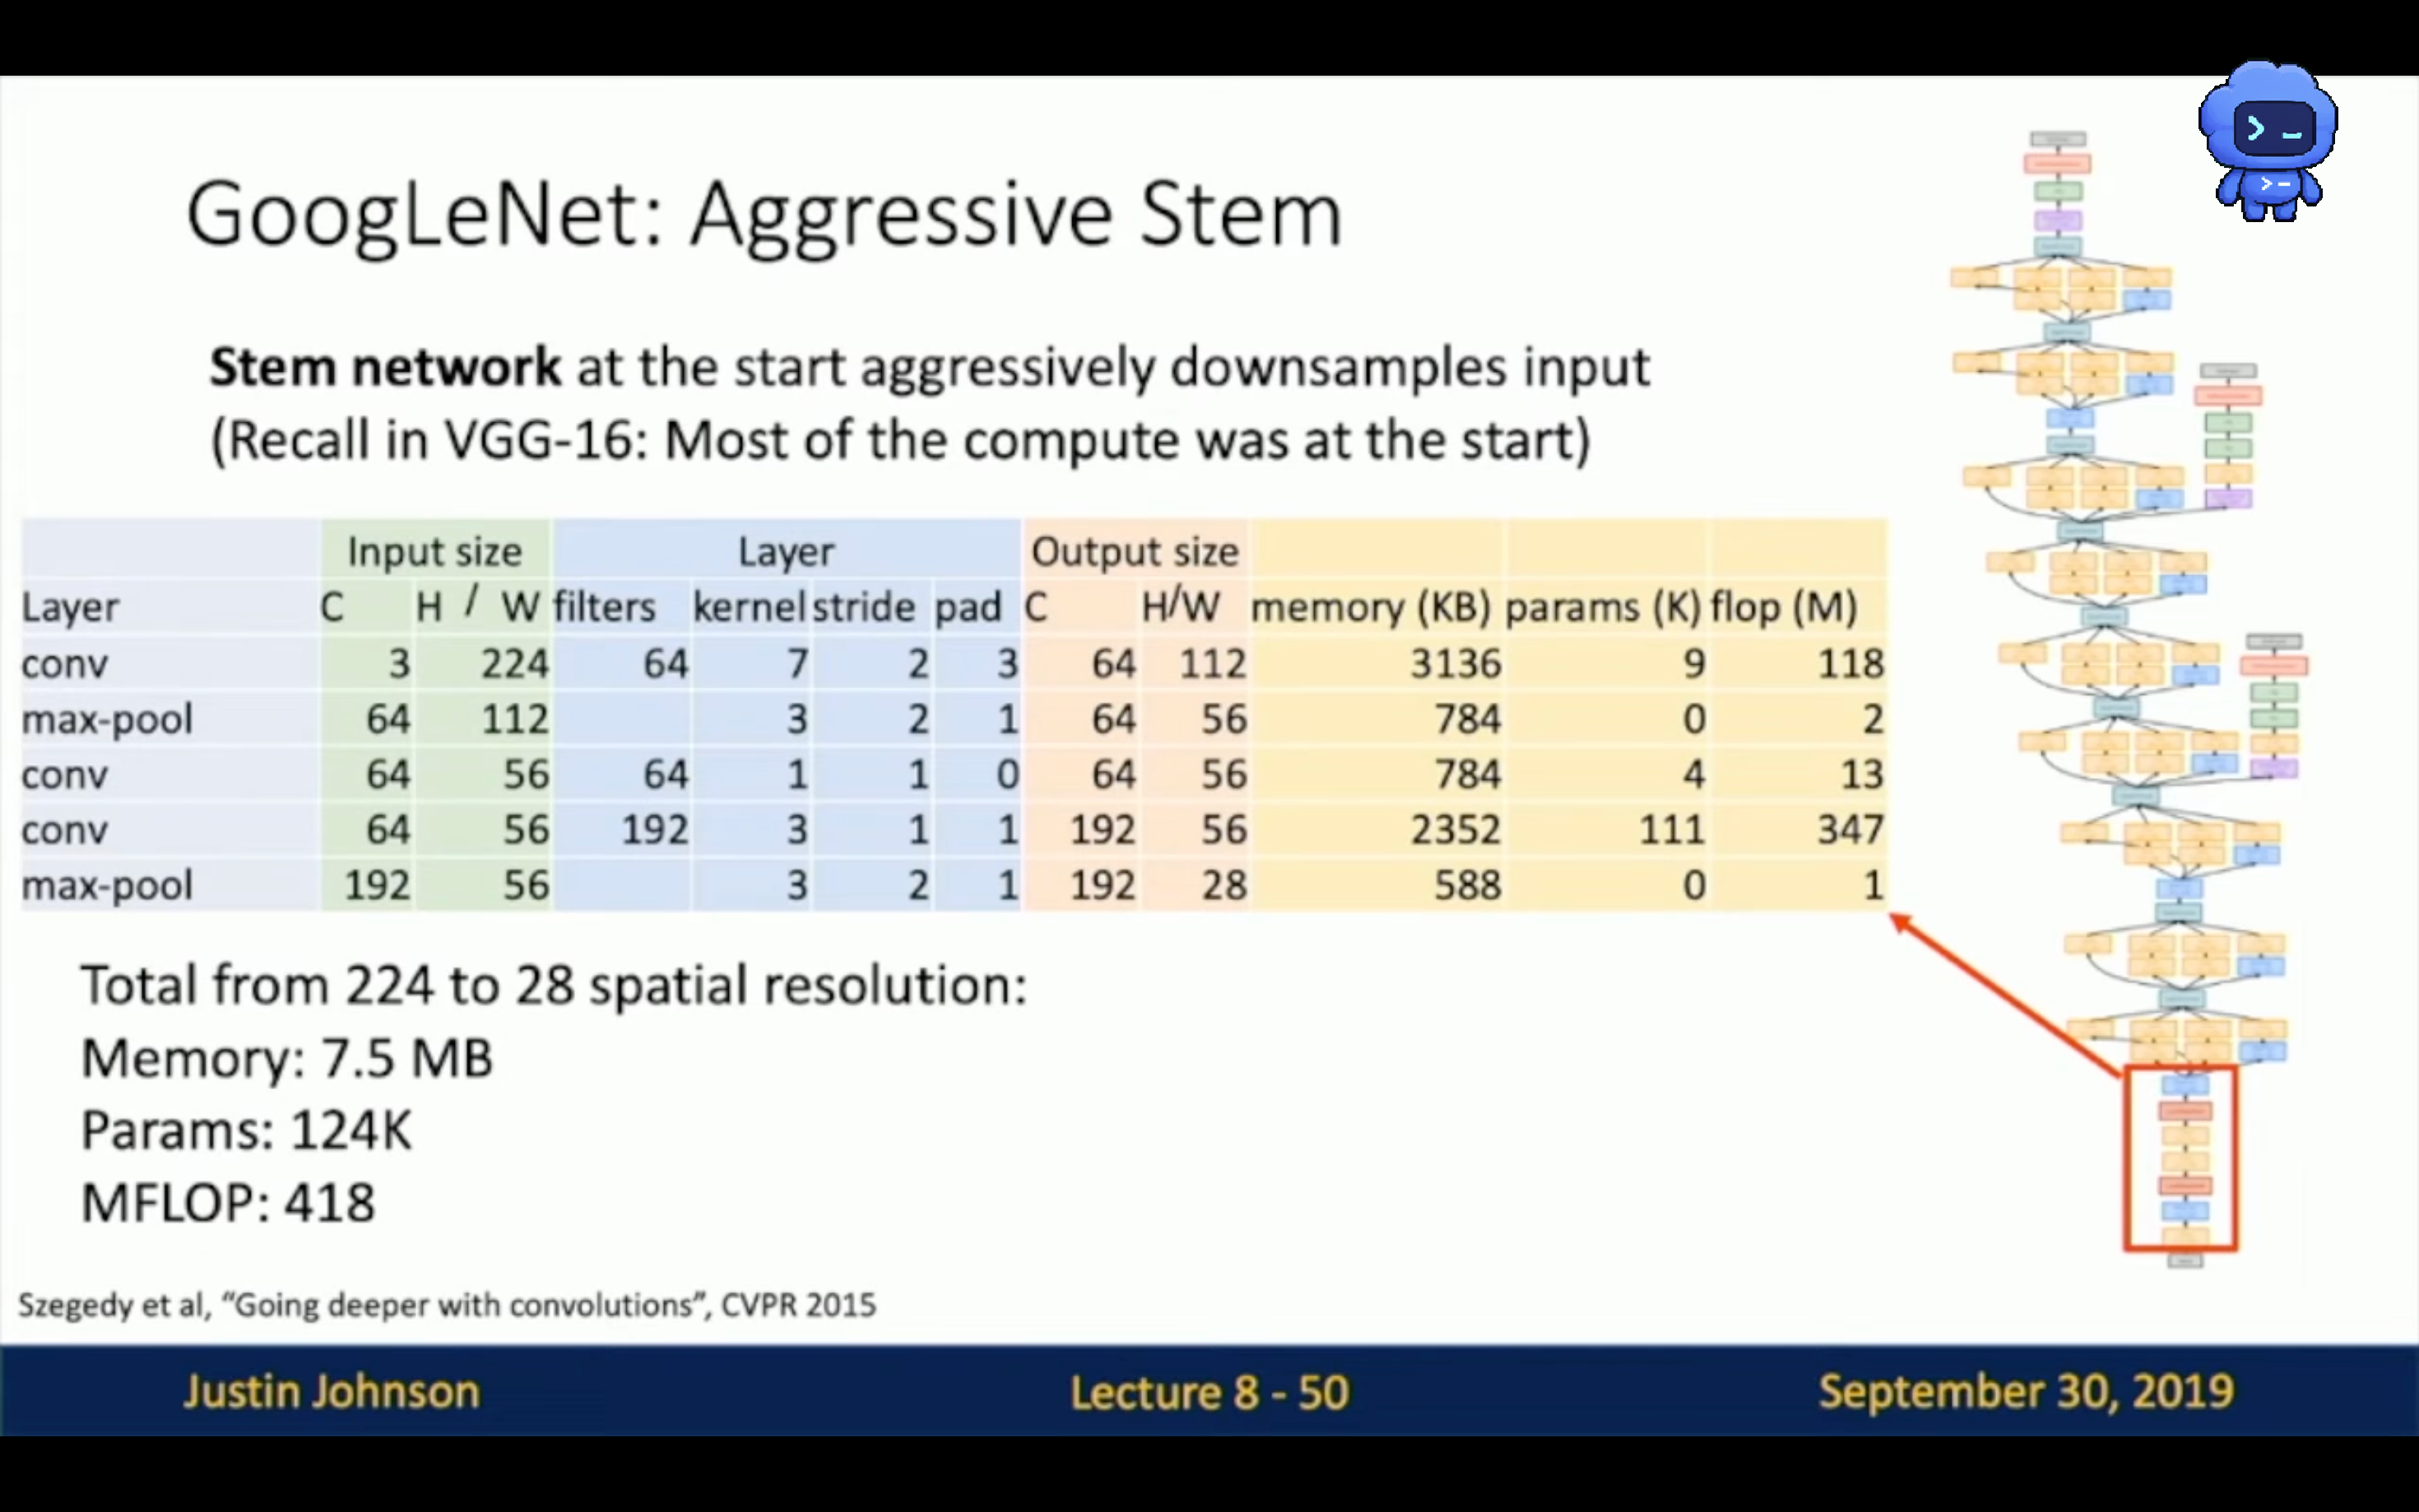

### Inception Module
取消kenel size超参，多尺寸kernel并行

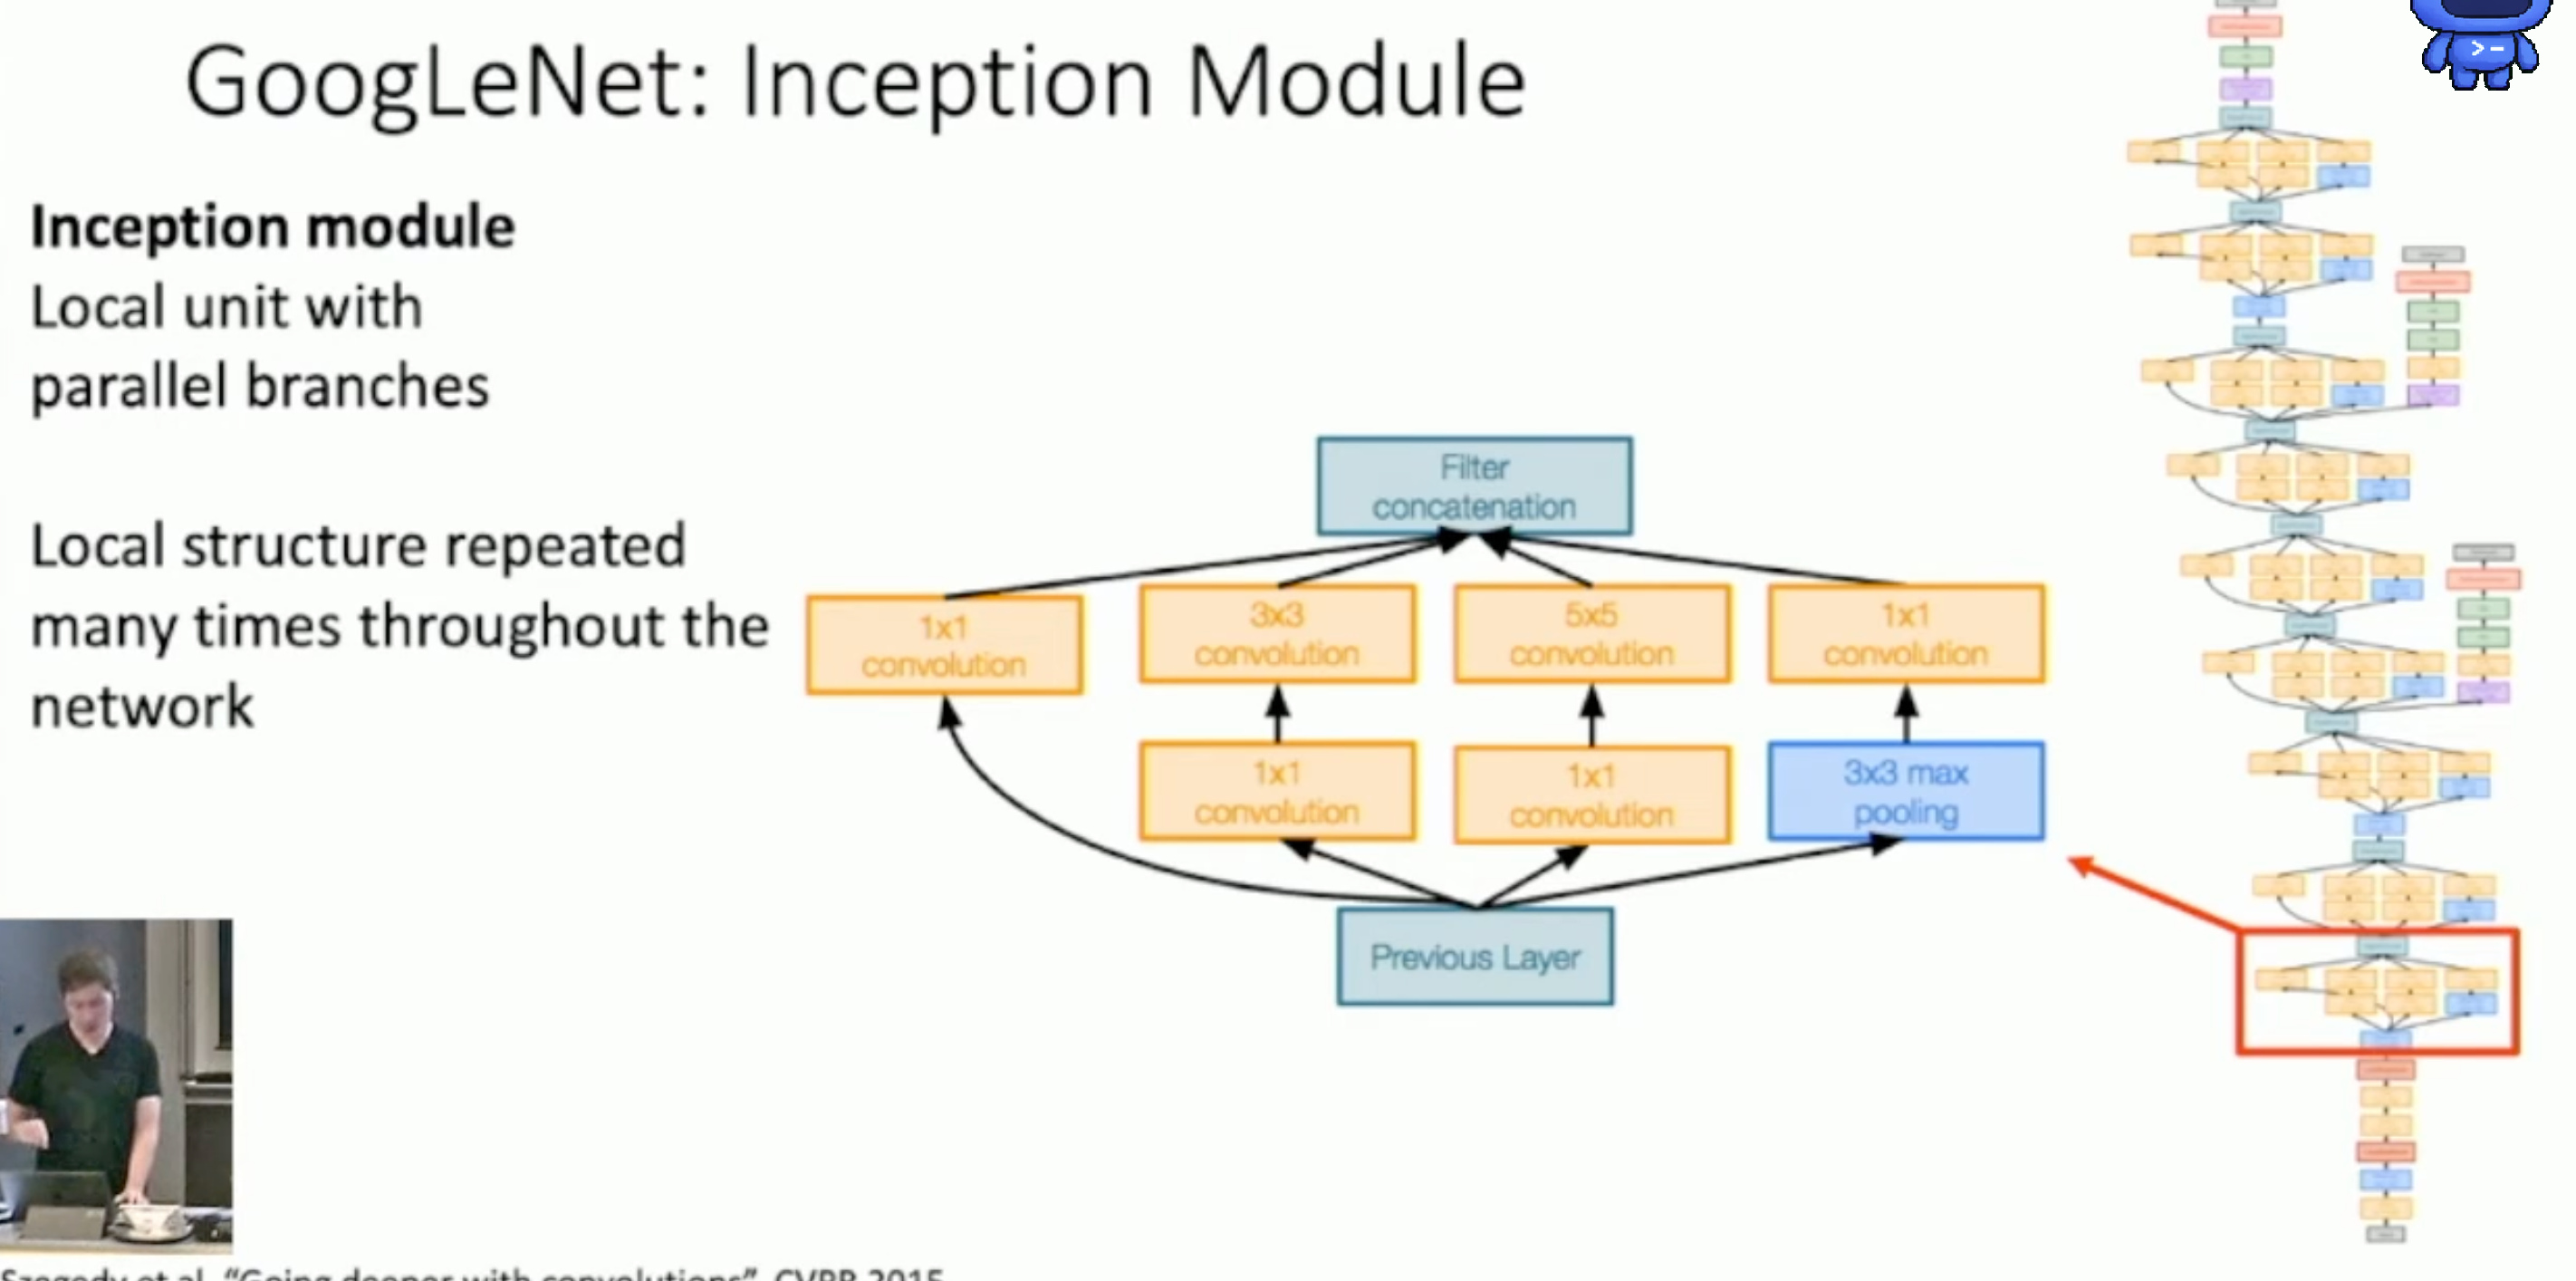

### Global Average Pooling
将尾部展平后fc替换为global average pooling（1\*1），大大减小了参数量。

最后再加一个fc层映射类别。

## ResNet(2015)

### Lead-in
deeper moedel does worse than shallow model, deep model is underfitting! 但是案例来说，deep model 至少应该和shallow model一样好（我们可以把shallow model的层给copy过来，然后把复杂的层给设为0，然后训练）

Hypothesis: Optimization Problem. 没有学到shallow model的identity function.

Solution: Change the network so learning identity functions with extra layers is easy.

### Structure
1. Residual Block
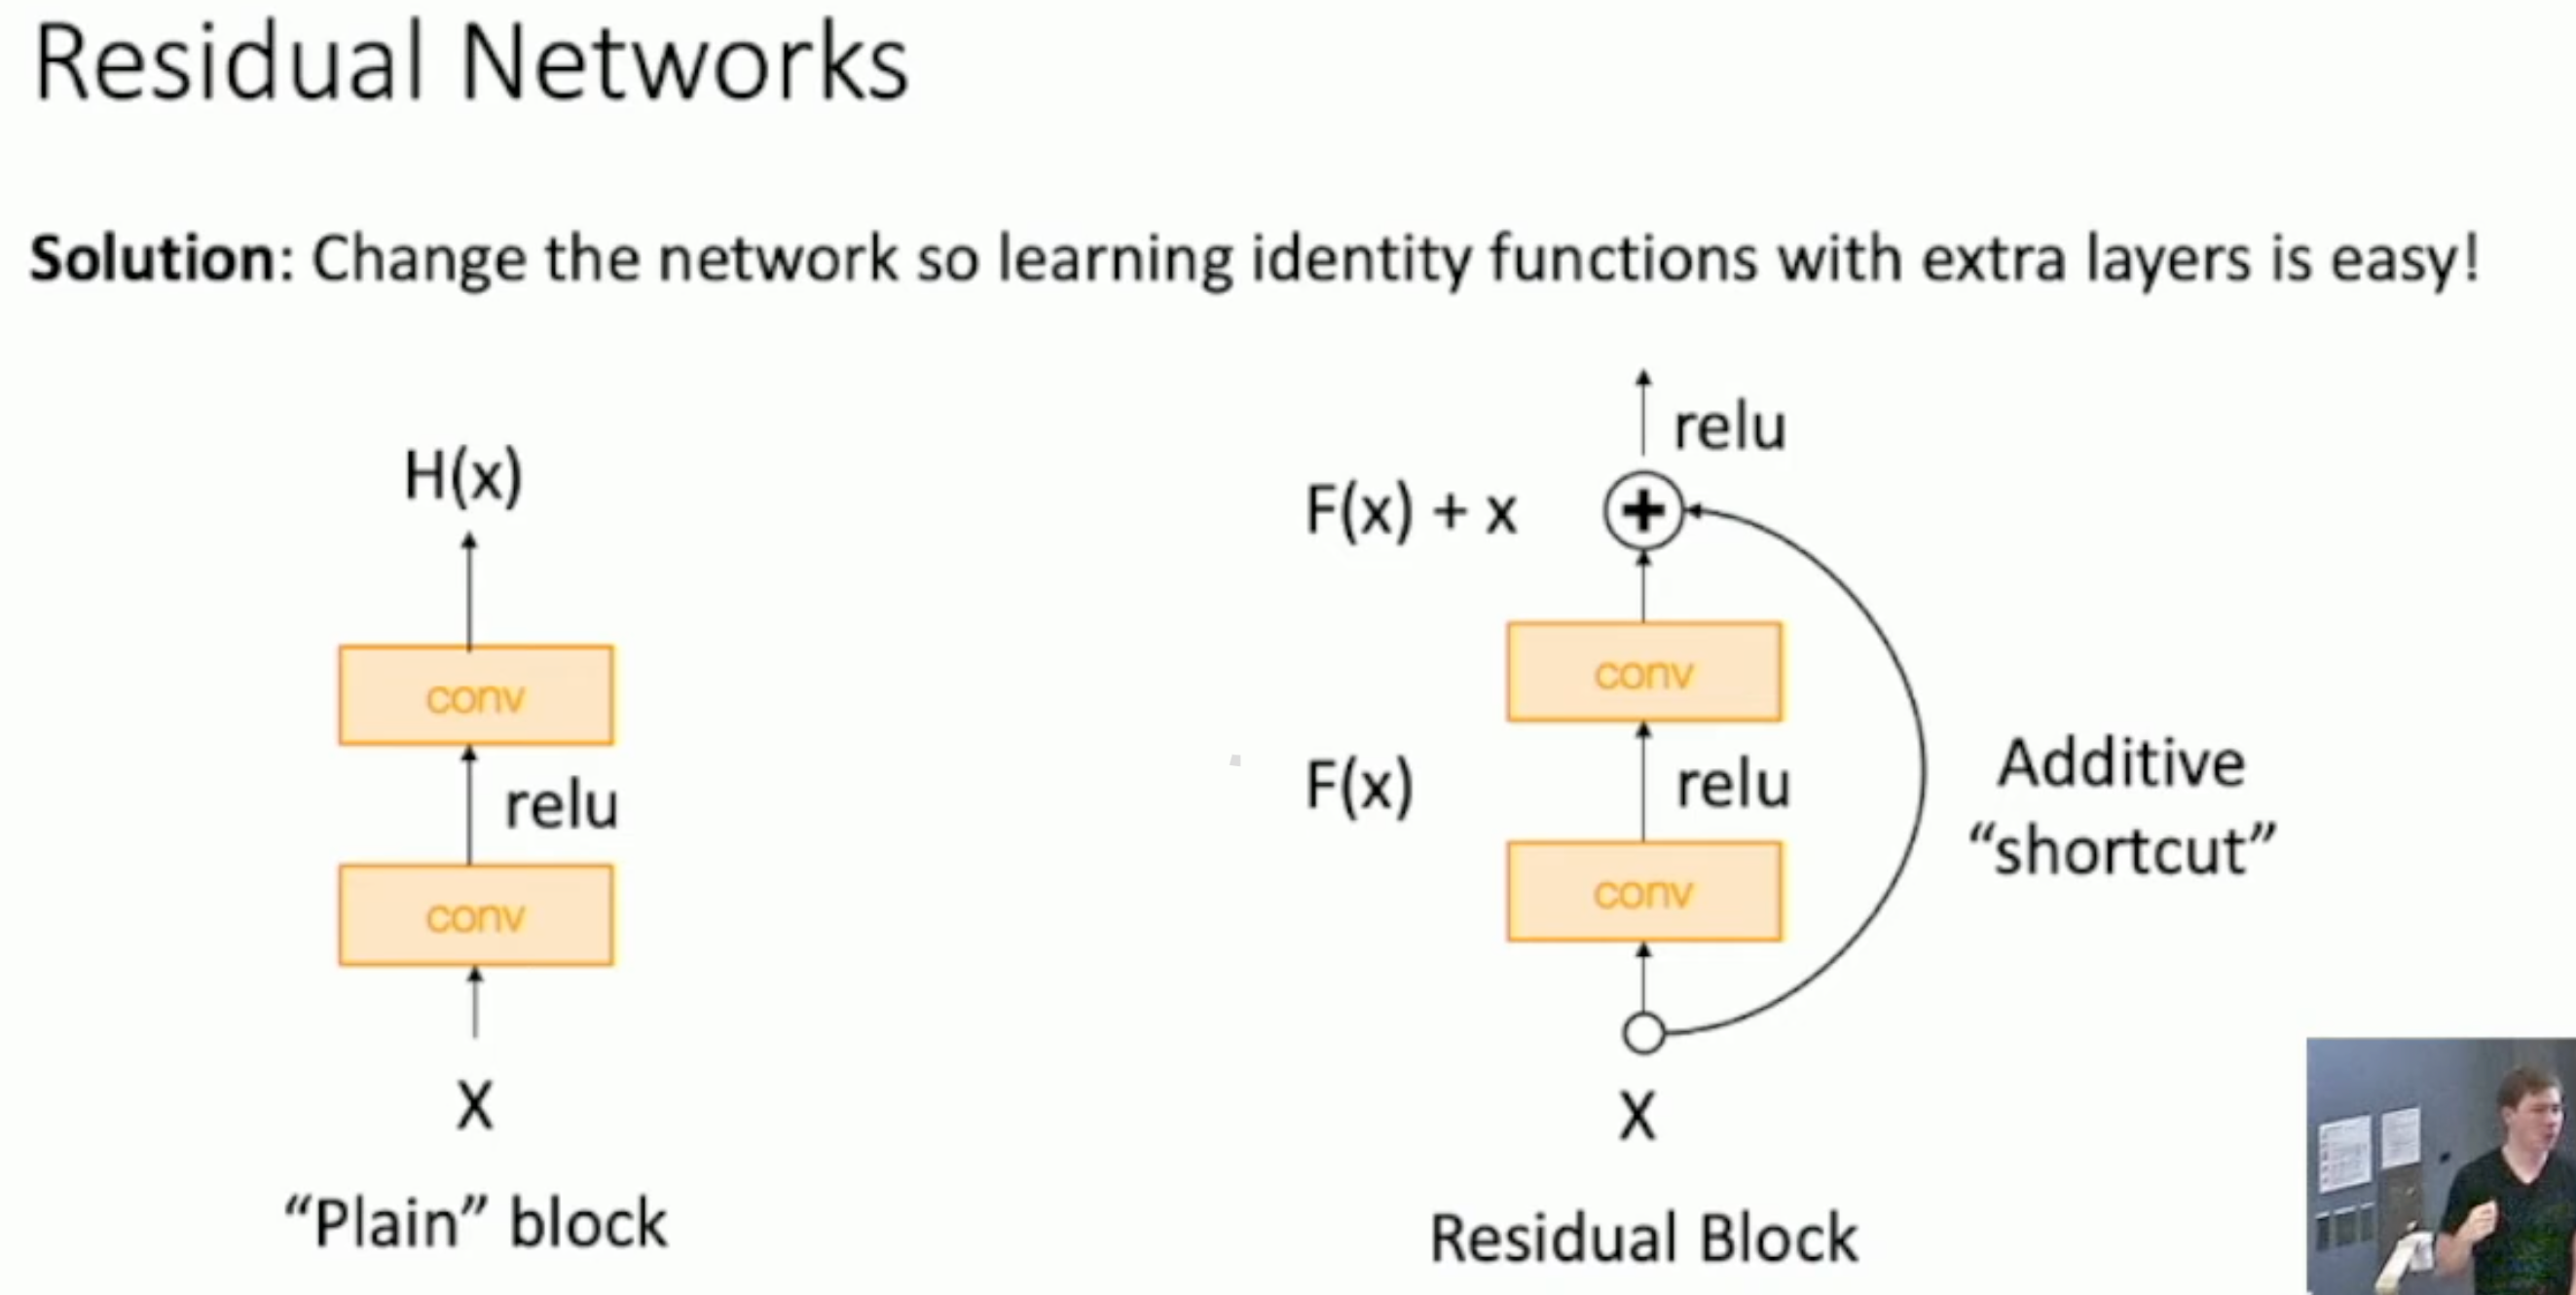

2. Residual Bottleneck Block
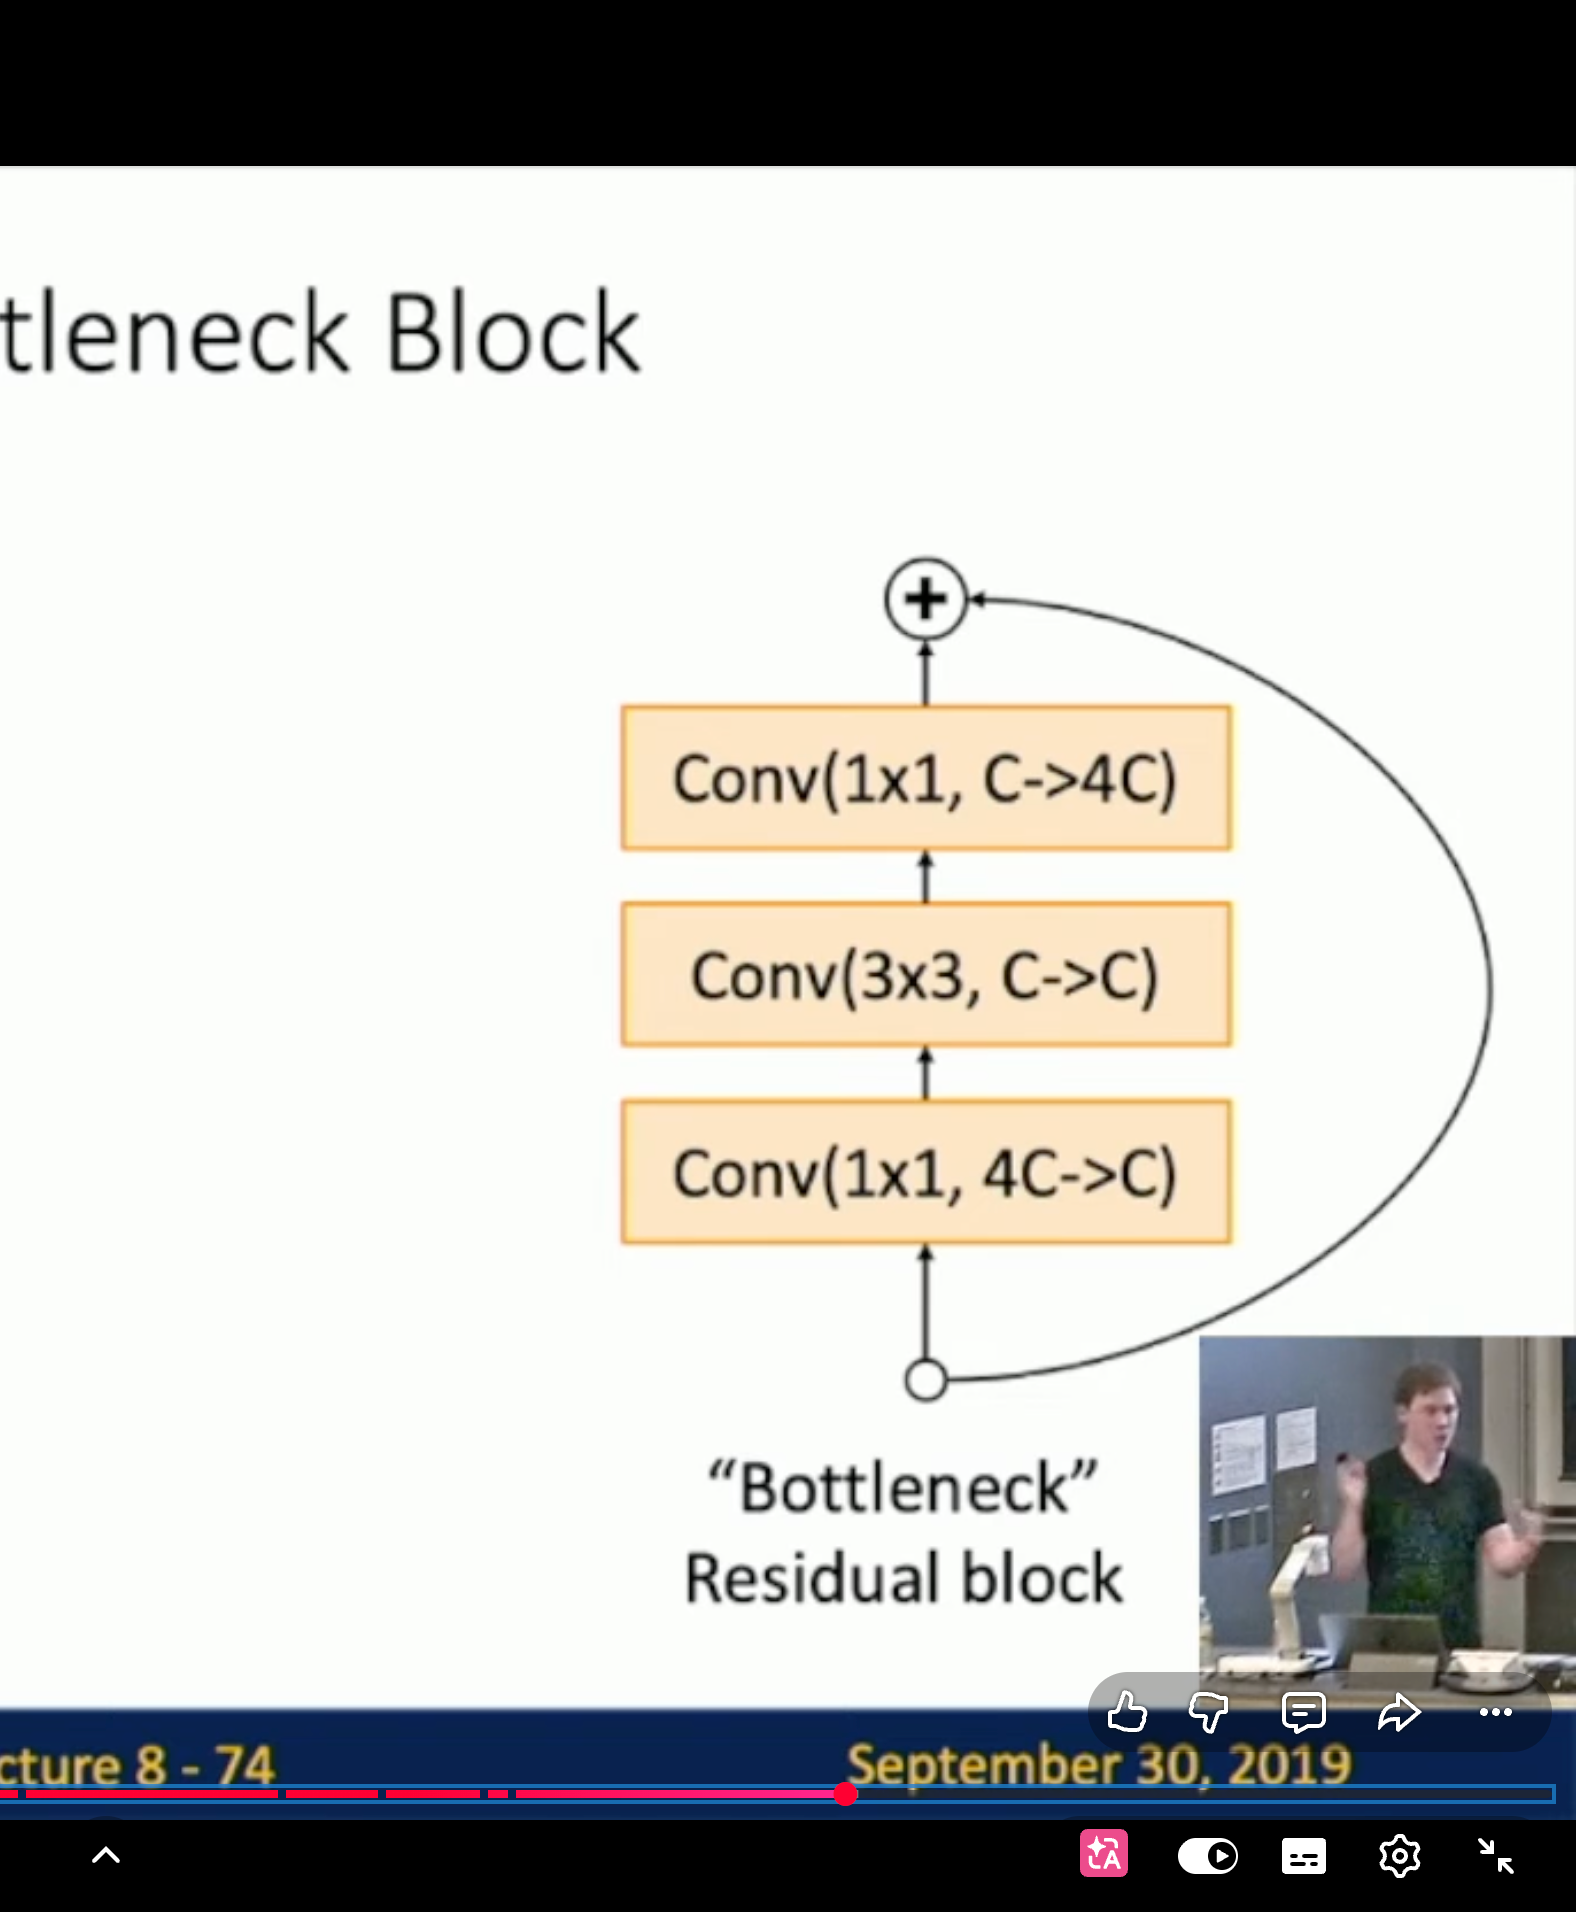

2. aggressive downsampling, and no fc at the end.(similar to GoogLeNet)   
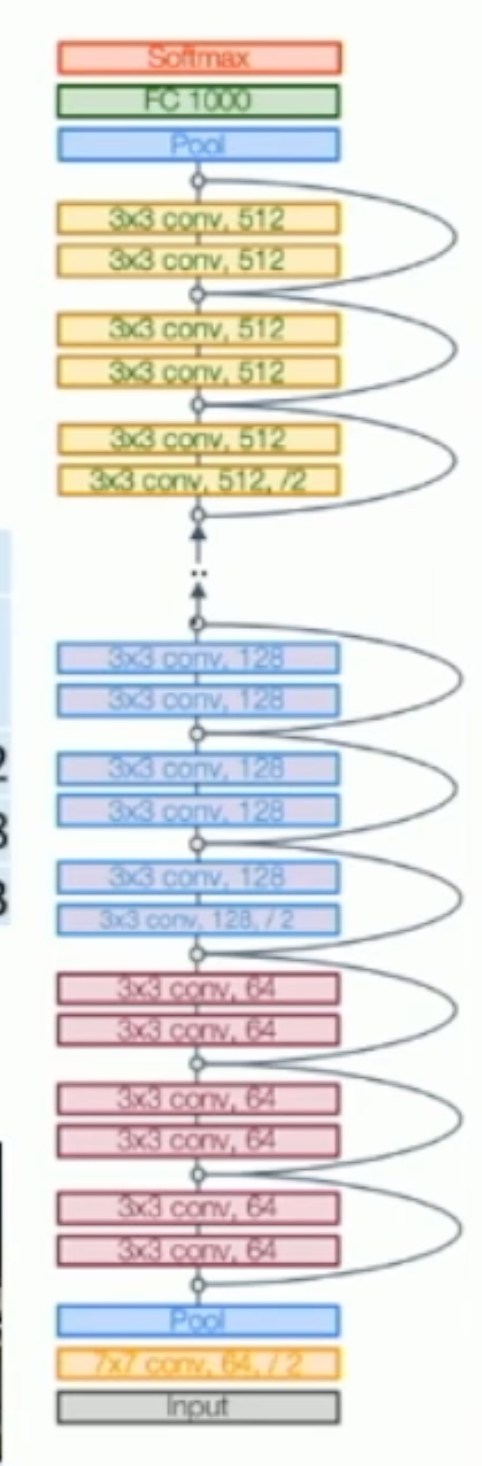